# TP - Clasificación de Texto con MLP (20 Newsgroups)
### Redes Neuronales / Deep Learning

Continuación del TP de Regresión Softmax: se reemplaza el modelo lineal por un **MLP** (perceptrón multicapa) y se buscan con **Optuna** (con *pruning*) los hiperparámetros de preprocesamiento, arquitectura y optimizador.

**Contenido**
1. Setup, datos y preprocesamiento (igual que el TP anterior).
2. Modelo MLP configurable (1 a 3 capas ocultas, neuronas por capa, función de activación).
3. Búsqueda con Optuna: preprocesamiento + `lr` + `batch_size` + arquitectura + optimizador (Adam, RMSprop, SGD) con sus momentos de orden 1 y 2. Incluye *pruning*.
4. Análisis de todos los trials: performance y tiempos.
5. Entrenamiento final con los mejores hiperparámetros y evaluación en test.
6. Experimento de overfitting (MLP grande, aparte de la búsqueda).
7. Comparación con Regresión Softmax (mismo hardware).

> Recomendado: usar GPU en Colab (*Entorno de ejecución → Cambiar tipo de entorno de ejecución*).

## 0. Setup

In [1]:
!pip install -q mlflow optuna

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 50.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

import mlflow
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)
if device.type == "cpu":
    print("ATENCIÓN: sin GPU el entrenamiento va a ser bastante más lento.")

Usando dispositivo: cuda


In [3]:
for recurso in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(recurso, quiet=True)

## Configuración general

Valores elegidos para que la búsqueda sea rápida. Se pueden aumentar si hay tiempo.

In [4]:
N_TRIALS = 30            # cantidad máxima de trials de Optuna
TIMEOUT_S = 20 * 60      # corta la búsqueda a los 20 minutos aunque no haya terminado
EPOCHS_SEARCH = 8        # épocas por trial (el pruning corta antes los trials malos)
EPOCHS_OVERFIT = 25      # épocas del experimento de overfitting
EPOCHS_SOFTMAX = 20      # épocas de la regresión softmax de comparación
EVAL_BATCH = 1024        # tamaño de lote para evaluar (no afecta el entrenamiento)

mlflow.end_run()  # por si quedó algún run abierto de una ejecución anterior
mlflow.set_experiment("mlp_20newsgroups")

2026/10/22 01:53:17 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/22 01:53:17 INFO mlflow.store.db.utils: Updating database tables
2026/10/22 01:53:22 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1792634002397, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792634002397, lifecycle_stage='active', name='mlp_20newsgroups', tags={}, trace_location=None, workspace='default'>

## 1. Datos: 20 Newsgroups

In [5]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
y_train_full = np.array(newsgroups_train.target)
y_test = np.array(newsgroups_test.target)
print(f"Clases: {NUM_CLASSES} | Train: {len(y_train_full)} | Test: {len(y_test)}")

Clases: 20 | Train: 11314 | Test: 7532


## 2. Preprocesamiento y vectorización (del TP anterior)

In [6]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)


def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [7]:
# Precalculamos el preprocesamiento para las 6 combinaciones (es lo más lento del pipeline)
t0 = time.perf_counter()
preprocessed_cache = {}
for remove_sw in [False, True]:
    for norm in ["none", "stem", "lemmatize"]:
        train_proc = [preprocess_text(t, remove_sw, norm) for t in newsgroups_train.data]
        test_proc = [preprocess_text(t, remove_sw, norm) for t in newsgroups_test.data]
        preprocessed_cache[(remove_sw, norm)] = (train_proc, test_proc)
        print("  listo:", (remove_sw, norm))
print(f"Preprocesamiento total: {time.perf_counter() - t0:.1f} s")

  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')
Preprocesamiento total: 209.1 s


In [8]:
# Partición train/validación fija para toda la búsqueda (misma que en el TP anterior)
idx_tr, idx_val = train_test_split(
    np.arange(len(y_train_full)), test_size=0.2, random_state=SEED, stratify=y_train_full
)
y_tr, y_val = y_train_full[idx_tr], y_train_full[idx_val]

# Cache de matrices TF-IDF (dispersas) para no revectorizar configuraciones repetidas
vectorized_cache = {}


def get_search_features(remove_sw, norm, ngram, max_features, min_df):
    key = (remove_sw, norm, ngram, max_features, min_df)
    if key not in vectorized_cache:
        train_texts, _ = preprocessed_cache[(remove_sw, norm)]
        tr_texts = [train_texts[i] for i in idx_tr]
        val_texts = [train_texts[i] for i in idx_val]
        X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram, max_features, min_df)
        vectorized_cache[key] = (X_tr, X_val)
    return vectorized_cache[key]


def to_device(X, y):
    # Matriz dispersa -> tensor denso en el dispositivo (los datos entran en memoria)
    X_t = torch.tensor(X.toarray(), dtype=torch.float32, device=device)
    y_t = torch.tensor(y, dtype=torch.long, device=device)
    return X_t, y_t

## 3. Modelo: MLP configurable

In [9]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "tanh": nn.Tanh,
    "leaky_relu": nn.LeakyReLU,
    "gelu": nn.GELU,
}


class MLP(nn.Module):
    """Capas ocultas Linear + activación, y una capa de salida que devuelve logits.
    Con hidden_sizes=[] es una regresión softmax (una sola capa lineal)."""

    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu"):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_sizes:
            layers += [nn.Linear(prev, h), ACTIVATIONS[activation]()]
            prev = h
        layers.append(nn.Linear(prev, num_classes))  # sin softmax: CrossEntropyLoss lo incluye
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Sanity check
_m = MLP(50, [32, 16], 20, "gelu")
assert _m(torch.randn(4, 50)).shape == (4, 20)
print(_m)
print("Parámetros:", count_params(_m))

MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=16, out_features=20, bias=True)
  )
)
Parámetros: 2500


In [10]:
def make_optimizer(name, params, lr, opt_kwargs):
    if name == "adam":
        return optim.Adam(params, lr=lr, betas=(opt_kwargs["beta1"], opt_kwargs["beta2"]))
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr, alpha=opt_kwargs["alpha"], momentum=opt_kwargs["momentum"])
    if name == "sgd":
        return optim.SGD(params, lr=lr, momentum=opt_kwargs["momentum"])
    raise ValueError(name)

## 4. Entrenamiento (con medición de tiempos y soporte de pruning)

In [11]:
criterion = nn.CrossEntropyLoss()


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    total_loss, correct = 0.0, 0
    for i in range(0, len(y), EVAL_BATCH):
        logits = model(X[i:i + EVAL_BATCH])
        total_loss += criterion(logits, y[i:i + EVAL_BATCH]).item() * len(logits)
        correct += (logits.argmax(1) == y[i:i + EVAL_BATCH]).sum().item()
    return total_loss / len(y), correct / len(y)


def train_model(model, X_tr, y_tr, X_val, y_val, optimizer, epochs, batch_size,
                trial=None, run_name="run", verbose=True):
    """Entrena y devuelve el historial por época. Si recibe un trial de Optuna,
    reporta val_acc en cada época y corta el entrenamiento si el pruner lo indica."""
    model.to(device)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    n = len(y_tr)
    for epoch in range(epochs):
        sync()
        t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(n, device=device)
        run_loss, correct = 0.0, 0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_tr[idx], y_tr[idx]
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(idx)
            correct += (logits.argmax(1) == yb).sum().item()
        sync()
        epoch_time = time.perf_counter() - t0

        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(run_loss / n)
        hist["train_acc"].append(correct / n)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        hist["epoch_time"].append(epoch_time)

        if verbose:
            print(f"[{run_name}] ep {epoch + 1}/{epochs} - train_loss {hist['train_loss'][-1]:.4f} "
                  f"train_acc {hist['train_acc'][-1]:.4f} - val_loss {val_loss:.4f} "
                  f"val_acc {val_acc:.4f} - {epoch_time:.2f} s")
        if mlflow.active_run() is not None:
            mlflow.log_metrics({k: hist[k][-1] for k in hist}, step=epoch)

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                trial.set_user_attr("history", hist)
                raise optuna.TrialPruned()
    return hist

## 5. Búsqueda de hiperparámetros con Optuna (con pruning)

- **Preprocesamiento (TP anterior):** `remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`.
- **Entrenamiento (TP anterior):** `lr`, `batch_size`.
- **Arquitectura:** `n_layers` (1 a 3), `n_units_l{i}` (neuronas de cada capa), `activation`.
- **Optimizador:** `adam` (`beta1` = momento de orden 1, `beta2` = momento de orden 2), `rmsprop` (`alpha` = decaimiento del promedio del gradiente al cuadrado, es decir, momento de orden 2; `momentum` = orden 1) y `sgd` (`momentum` = orden 1).
- **Pruning:** `MedianPruner` corta un trial si su `val_acc` en una época queda por debajo de la mediana de los trials anteriores en esa misma época.
- El valor objetivo es la **mejor** `val_acc` del trial; se guarda también la época en que se alcanzó.

In [12]:
def objective(trial):
    # --- Preprocesamiento (TP anterior) ---
    remove_sw = trial.suggest_categorical("remove_stopwords", [False, True])
    norm = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_name = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram = (1, 1) if ngram_name == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])

    # --- Entrenamiento (TP anterior) ---
    lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # --- Arquitectura ---
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden = [trial.suggest_categorical(f"n_units_l{i}", [64, 128, 256, 512]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", list(ACTIVATIONS))

    # --- Optimizador y momentos ---
    opt_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    if opt_name == "adam":
        opt_kwargs = {"beta1": trial.suggest_float("adam_beta1", 0.8, 0.99),
                      "beta2": trial.suggest_float("adam_beta2", 0.9, 0.9999)}
    elif opt_name == "rmsprop":
        opt_kwargs = {"alpha": trial.suggest_float("rmsprop_alpha", 0.8, 0.999),
                      "momentum": trial.suggest_float("rmsprop_momentum", 0.0, 0.9)}
    else:
        opt_kwargs = {"momentum": trial.suggest_float("sgd_momentum", 0.0, 0.95)}

    # --- Datos ---
    t0 = time.perf_counter()
    X_tr_sp, X_val_sp = get_search_features(remove_sw, norm, ngram, max_features, min_df)
    X_tr, y_tr_t = to_device(X_tr_sp, y_tr)
    X_val, y_val_t = to_device(X_val_sp, y_val)
    trial.set_user_attr("prep_time_s", time.perf_counter() - t0)

    # --- Modelo y entrenamiento ---
    torch.manual_seed(SEED + trial.number)
    model = MLP(X_tr.shape[1], hidden, NUM_CLASSES, activation)
    optimizer = make_optimizer(opt_name, model.parameters(), lr, opt_kwargs)
    trial.set_user_attr("n_params", count_params(model))

    with mlflow.start_run(run_name=f"trial_{trial.number}"):
        mlflow.log_params(trial.params)
        t1 = time.perf_counter()
        try:
            hist = train_model(model, X_tr, y_tr_t, X_val, y_val_t, optimizer, EPOCHS_SEARCH,
                               batch_size, trial=trial, run_name=f"trial_{trial.number}", verbose=False)
        finally:
            trial.set_user_attr("train_time_s", time.perf_counter() - t1)
            mlflow.log_metric("train_time_s", time.perf_counter() - t1)

    best_epoch = int(np.argmax(hist["val_acc"])) + 1
    trial.set_user_attr("history", hist)
    trial.set_user_attr("best_epoch", best_epoch)
    return max(hist["val_acc"])

In [13]:
optuna.logging.set_verbosity(optuna.logging.INFO)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
)
t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_S)
search_time = time.perf_counter() - t0

states = pd.Series([t.state.name for t in study.trials]).value_counts()
print(f"\nBúsqueda: {search_time:.1f} s | trials por estado:\n{states.to_string()}")
print("\nMejor val_acc:", round(study.best_value, 4))
print("Mejor época:", study.best_trial.user_attrs["best_epoch"])
print("Mejores hiperparámetros:", study.best_params)

[I 2026-10-22 01:57:09,548] A new study created in memory with name: no-name-4864593c-bde1-4548-9cfe-4162959dc0a0
[I 2026-10-22 01:57:19,188] Trial 0 finished with value: 0.6071586389748121 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'lr': 0.0004335281794951569, 'batch_size': 128, 'n_layers': 2, 'n_units_l0': 256, 'n_units_l1': 512, 'activation': 'leaky_relu', 'optimizer': 'adam', 'adam_beta1': 0.9802882520781333, 'adam_beta2': 0.9964666401041485}. Best is trial 0 with value: 0.6071586389748121.
[I 2026-10-22 01:57:27,892] Trial 1 finished with value: 0.6040653999116218 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 1, 'lr': 0.004366473592979638, 'batch_size': 64, 'n_layers': 3, 'n_units_l0': 256, 'n_units_l1': 512, 'n_units_l2': 128, 'activation': 'leaky_relu', 'optimizer': 'adam', 'adam_beta1': 0.8010492022534845, 'adam_bet


Búsqueda: 161.5 s | trials por estado:
COMPLETE    17
PRUNED      13

Mejor val_acc: 0.7428
Mejor época: 6
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 10000, 'min_df': 5, 'lr': 0.0012968082705573276, 'batch_size': 64, 'n_layers': 1, 'n_units_l0': 64, 'activation': 'tanh', 'optimizer': 'adam', 'adam_beta1': 0.8728720199812425, 'adam_beta2': 0.9359777836683684}


## 6. Análisis de todos los trials: performance y tiempos

In [14]:
rows = []
for t in study.trials:
    if t.state.name not in ("COMPLETE", "PRUNED"):
        continue
    h = t.user_attrs.get("history", {})
    epochs_run = len(h.get("val_acc", []))
    if epochs_run == 0:
        continue
    p = t.params
    rows.append({
        "trial": t.number,
        "estado": t.state.name,
        "best_val_acc": max(h["val_acc"]),
        "best_epoch": int(np.argmax(h["val_acc"])) + 1,
        "train_acc_final": h["train_acc"][-1],
        "epocas": epochs_run,
        "t_entrenamiento_s": t.user_attrs.get("train_time_s", np.nan),
        "t_por_epoca_s": float(np.mean(h["epoch_time"])),
        "n_params": t.user_attrs.get("n_params"),
        "optimizer": p["optimizer"],
        "activation": p["activation"],
        "n_layers": p["n_layers"],
        "neuronas": "-".join(str(p[f"n_units_l{i}"]) for i in range(p["n_layers"])),
        "lr": p["lr"],
        "batch_size": p["batch_size"],
        "max_features": p["max_features"],
        "ngram": p["ngram_range"],
        "stopwords": p["remove_stopwords"],
        "norm": p["normalization"],
    })
df_trials = pd.DataFrame(rows).sort_values("best_val_acc", ascending=False).reset_index(drop=True)
df_trials["gap_train_val"] = df_trials["train_acc_final"] - df_trials["best_val_acc"]
pd.set_option("display.width", 250)
df_trials.round(4)

,trial,estado,best_val_acc,best_epoch,train_acc_final,epocas,t_entrenamiento_s,t_por_epoca_s,n_params,optimizer,activation,n_layers,neuronas,lr,batch_size,max_features,ngram,stopwords,norm,gap_train_val
0,27,COMPLETE,0.7428,6,0.9416,8,2.0327,0.2372,641364,adam,tanh,1,64,0.0013,64,10000,1_2gram,True,stem,0.1987
1,28,COMPLETE,0.7371,6,0.9481,8,1.0981,0.1203,641364,adam,tanh,1,64,0.0017,128,10000,1_2gram,True,lemmatize,0.2110
2,29,COMPLETE,0.7344,8,0.8613,8,1.1116,0.1215,641364,adam,tanh,1,64,0.0008,128,10000,1_2gram,True,stem,0.1269
3,19,COMPLETE,0.7291,2,0.9718,8,1.0432,0.1146,641364,adam,tanh,1,64,0.0044,128,10000,1_2gram,True,none,0.2427
4,18,COMPLETE,0.7114,2,0.9708,8,2.2727,0.2677,661844,adam,tanh,2,64-256,0.0024,64,10000,1_2gram,True,stem,0.2594
5,22,COMPLETE,0.7004,2,0.9699,8,4.2754,0.5179,661844,adam,tanh,2,64-256,0.0035,32,10000,1_2gram,True,stem,0.2696
6,16,COMPLETE,0.6805,3,0.9735,8,2.3612,0.2759,683604,adam,tanh,2,64-512,0.0010,64,10000,1_2gram,False,stem,0.2930
7,3,COMPLETE,0.6712,2,0.9727,8,2.2508,0.2647,645524,adam,tanh,2,64-64,0.0019,64,10000,1_2gram,False,stem,0.3015
8,23,COMPLETE,0.6690,3,0.9567,8,4.6479,0.5626,1318292,adam,tanh,2,128-256,0.0155,32,10000,1_2gram,True,stem,0.2877
9,7,COMPLETE,0.6664,7,0.9565,8,5.1475,0.6258,707476,rmsprop,gelu,3,64-512-64,0.0070,32,10000,1gram,False,none,0.2901


In [15]:
# Promedio de la mejor val_acc por cada hiperparámetro (solo trials completos)
completos = df_trials[df_trials["estado"] == "COMPLETE"]
for col in ["optimizer", "activation", "n_layers", "batch_size", "max_features", "ngram", "stopwords", "norm"]:
    resumen = completos.groupby(col).agg(n=("trial", "count"),
                                         val_acc_media=("best_val_acc", "mean"),
                                         val_acc_max=("best_val_acc", "max"),
                                         t_por_epoca_media=("t_por_epoca_s", "mean"))
    print(f"\n=== {col} ===")
    print(resumen.round(4).to_string())


=== optimizer ===
            n  val_acc_media  val_acc_max  t_por_epoca_media
optimizer                                                   
adam       13         0.6836       0.7428             0.2632
rmsprop     3         0.6456       0.6664             0.4935
sgd         1         0.0530       0.0530             0.5183

=== activation ===
             n  val_acc_media  val_acc_max  t_por_epoca_media
activation                                                   
gelu         2         0.6584       0.6664             0.6224
leaky_relu   2         0.6056       0.6072             0.2608
relu         1         0.0530       0.0530             0.5183
tanh        12         0.6913       0.7428             0.2613

=== n_layers ===
          n  val_acc_media  val_acc_max  t_por_epoca_media
n_layers                                                  
1         6         0.7003       0.7428             0.1585
2         6         0.6733       0.7114             0.3485
3         5         0.5271    

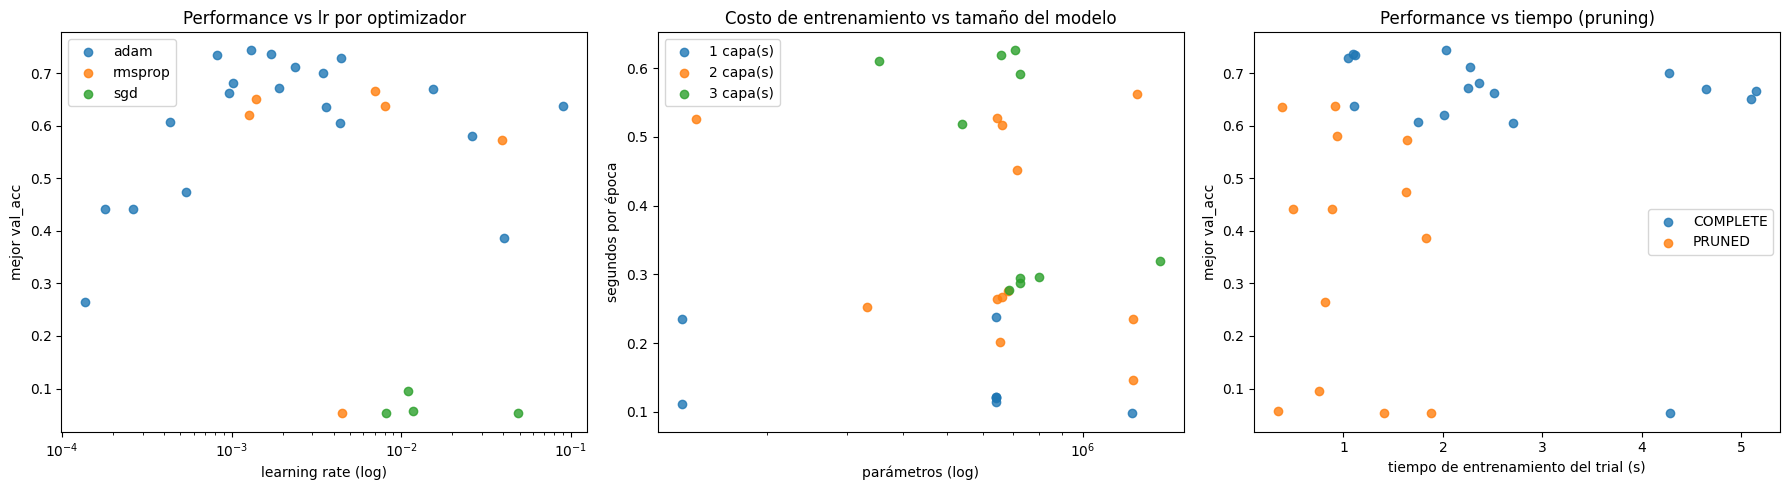

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Performance vs learning rate, por optimizador
for opt_name, g in df_trials.groupby("optimizer"):
    axes[0].scatter(g["lr"], g["best_val_acc"], label=opt_name, alpha=0.8)
axes[0].set_xscale("log")
axes[0].set_xlabel("learning rate (log)")
axes[0].set_ylabel("mejor val_acc")
axes[0].set_title("Performance vs lr por optimizador")
axes[0].legend()

# 2) Tiempo por época vs cantidad de parámetros
for n_l, g in df_trials.groupby("n_layers"):
    axes[1].scatter(g["n_params"], g["t_por_epoca_s"], label=f"{n_l} capa(s)", alpha=0.8)
axes[1].set_xscale("log")
axes[1].set_xlabel("parámetros (log)")
axes[1].set_ylabel("segundos por época")
axes[1].set_title("Costo de entrenamiento vs tamaño del modelo")
axes[1].legend()

# 3) Performance vs tiempo total de entrenamiento (completos vs podados)
for estado, g in df_trials.groupby("estado"):
    axes[2].scatter(g["t_entrenamiento_s"], g["best_val_acc"], label=estado, alpha=0.8)
axes[2].set_xlabel("tiempo de entrenamiento del trial (s)")
axes[2].set_ylabel("mejor val_acc")
axes[2].set_title("Performance vs tiempo (pruning)")
axes[2].legend()

plt.tight_layout()
plt.show()

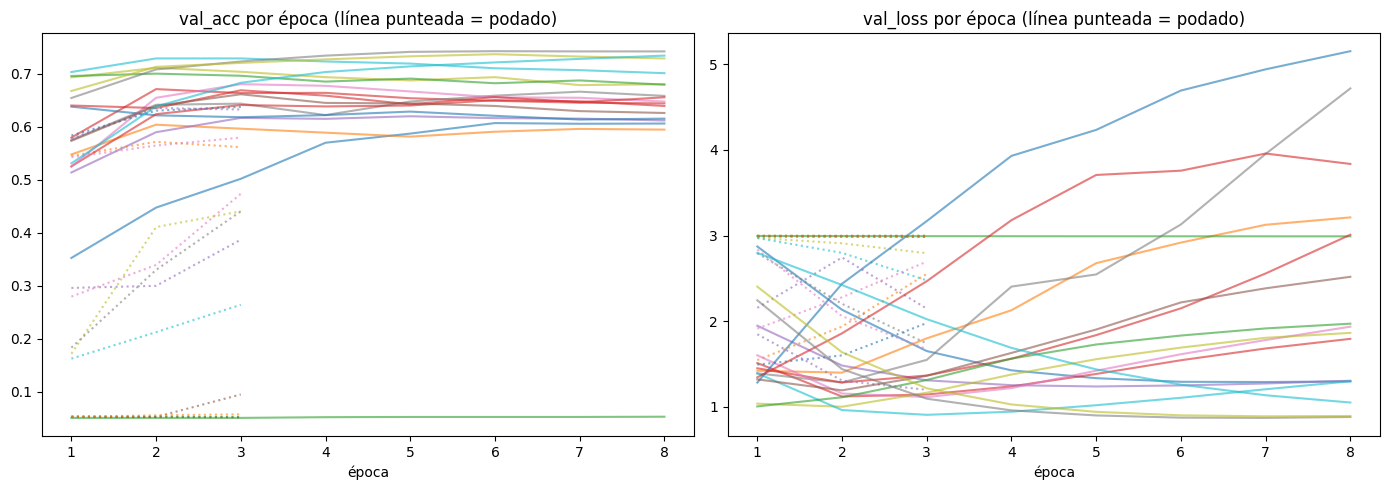

In [17]:
# Curvas de validación de todos los trials: los podados se ven como curvas cortadas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for t in study.trials:
    h = t.user_attrs.get("history")
    if not h:
        continue
    estilo = "-" if t.state.name == "COMPLETE" else ":"
    ep = range(1, len(h["val_acc"]) + 1)
    axes[0].plot(ep, h["val_acc"], estilo, alpha=0.6)
    axes[1].plot(ep, h["val_loss"], estilo, alpha=0.6)
axes[0].set_title("val_acc por época (línea punteada = podado)")
axes[1].set_title("val_loss por época (línea punteada = podado)")
for ax in axes:
    ax.set_xlabel("época")
plt.tight_layout()
plt.show()

In [18]:
# Tiempo ahorrado por el pruning (estimado con el tiempo por época de cada trial podado)
podados = df_trials[df_trials["estado"] == "PRUNED"]
ahorro = ((EPOCHS_SEARCH - podados["epocas"]) * podados["t_por_epoca_s"]).sum()
print(f"Trials podados: {len(podados)} de {len(df_trials)}")
print(f"Épocas evitadas: {(EPOCHS_SEARCH - podados['epocas']).sum()}")
print(f"Tiempo de entrenamiento ahorrado (estimado): {ahorro:.1f} s")
print(f"Tiempo total de entrenamiento de los trials: {df_trials['t_entrenamiento_s'].sum():.1f} s")

Trials podados: 13 de 30
Épocas evitadas: 65
Tiempo de entrenamiento ahorrado (estimado): 22.0 s
Tiempo total de entrenamiento de los trials: 59.6 s


## Análisis de la búsqueda

Se probaron 30 configuraciones en 143 s: 17 terminaron y 13 se cortaron antes por pruning. La mejor (val_acc 0.7428) es una red de 1 sola capa de 64 neuronas con tanh y Adam.

- **Capas:** los 4 mejores modelos tienen 1 capa. Con más capas el resultado empeora en promedio (0.70 con 1 capa, 0.67 con 2 y 0.53 con 3). Para este problema, más capas no ayudan.
- **Optimizador:** Adam fue el más estable. RMSprop funcionó peor y SGD no aprendió en ninguno de sus 4 intentos (quedó en 0.05, que es adivinar al azar entre 20 clases). Probablemente SGD necesitaba un learning rate más alto que el rango probado.
- **Activación:** tanh está en todos los mejores modelos, pero ReLU casi no se probó, así que no se puede decir que sea peor.
- **Preprocesamiento:** igual que con la regresión softmax, usar 10000 palabras fue lo mejor.
- **Tiempos:** lo que más influye en el tiempo por época es el batch size. Con 128 tarda la mitad que con 64, y con 64 la mitad que con 32. El tamaño de la red influye poco.
- **Sobreajuste:** muchos modelos llegan a su mejor resultado en las épocas 2 o 3 y después empeoran en validación mientras siguen mejorando en train.
- **Pruning:** ahorró unos 20 s de entrenamiento. Pero la mayor parte de los 143 s se usó en preparar los datos de cada trial, no en entrenar. También cortó algunos modelos que iban razonablemente bien.

## 7. Entrenamiento final con los mejores hiperparámetros

Se entrena con **todo** el train y se evalúa en test. La cantidad de épocas es la época en la que el mejor trial alcanzó su mejor `val_acc` (equivale a un *early stopping* decidido en validación, sin mirar el test).

In [19]:
bp = study.best_params
BEST_EPOCHS = study.best_trial.user_attrs["best_epoch"]
best_ngram = (1, 1) if bp["ngram_range"] == "1gram" else (1, 2)
best_hidden = [bp[f"n_units_l{i}"] for i in range(bp["n_layers"])]
if bp["optimizer"] == "adam":
    best_opt_kwargs = {"beta1": bp["adam_beta1"], "beta2": bp["adam_beta2"]}
elif bp["optimizer"] == "rmsprop":
    best_opt_kwargs = {"alpha": bp["rmsprop_alpha"], "momentum": bp["rmsprop_momentum"]}
else:
    best_opt_kwargs = {"momentum": bp["sgd_momentum"]}

train_texts, test_texts = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
X_train_sp, X_test_sp, vectorizer_final = vectorize_data(
    train_texts, test_texts, best_ngram, bp["max_features"], bp["min_df"])
X_train_t, y_train_t = to_device(X_train_sp, y_train_full)
X_test_t, y_test_t = to_device(X_test_sp, y_test)

torch.manual_seed(SEED)
mlp_final = MLP(X_train_t.shape[1], best_hidden, NUM_CLASSES, bp["activation"])
opt_final = make_optimizer(bp["optimizer"], mlp_final.parameters(), bp["lr"], best_opt_kwargs)
print(mlp_final)
print("Parámetros:", count_params(mlp_final), "| Épocas:", BEST_EPOCHS)

with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params({**bp, "epochs": BEST_EPOCHS})
    t0 = time.perf_counter()
    hist_final = train_model(mlp_final, X_train_t, y_train_t, X_test_t, y_test_t, opt_final,
                             BEST_EPOCHS, bp["batch_size"], run_name="mlp_final")
    mlp_final_time = time.perf_counter() - t0
    mlflow.log_metric("train_time_s", mlp_final_time)
print(f"Tiempo de entrenamiento final: {mlp_final_time:.1f} s")

MLP(
  (net): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=20, bias=True)
  )
)
Parámetros: 641364 | Épocas: 6
[mlp_final] ep 1/6 - train_loss 2.5770 train_acc 0.4899 - val_loss 2.0664 val_acc 0.6324 - 0.30 s
[mlp_final] ep 2/6 - train_loss 1.4534 train_acc 0.7523 - val_loss 1.3674 val_acc 0.6695 - 0.30 s
[mlp_final] ep 3/6 - train_loss 0.8853 train_acc 0.8055 - val_loss 1.1518 val_acc 0.6823 - 0.29 s
[mlp_final] ep 4/6 - train_loss 0.6303 train_acc 0.8487 - val_loss 1.0889 val_acc 0.6881 - 0.29 s
[mlp_final] ep 5/6 - train_loss 0.4785 train_acc 0.8836 - val_loss 1.0845 val_acc 0.6889 - 0.28 s
[mlp_final] ep 6/6 - train_loss 0.3734 train_acc 0.9093 - val_loss 1.1013 val_acc 0.6891 - 0.30 s
Tiempo de entrenamiento final: 1.9 s


In [21]:
with torch.no_grad():
    mlp_final.eval()
    preds = torch.cat([mlp_final(X_test_t[i:i + EVAL_BATCH]).argmax(1)
                       for i in range(0, len(y_test), EVAL_BATCH)]).cpu().numpy()
mlp_test_acc = accuracy_score(y_test, preds)
print(f"Accuracy en test (MLP): {mlp_test_acc:.4f}\n")
print(classification_report(y_test, preds, target_names=class_names))

cm = confusion_matrix(y_test, preds)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
print("Pares más confundidos:")
for i in np.argsort(cm_off, axis=None)[::-1][:10]:
    real, pred = divmod(i, NUM_CLASSES)
    print(f"{class_names[real]:>25} -> {class_names[pred]:<25} {cm_off[real, pred]}")

Accuracy en test (MLP): 0.6891

                          precision    recall  f1-score   support

             alt.atheism       0.54      0.50      0.52       319
           comp.graphics       0.65      0.67      0.66       389
 comp.os.ms-windows.misc       0.65      0.60      0.62       394
comp.sys.ibm.pc.hardware       0.68      0.59      0.63       392
   comp.sys.mac.hardware       0.69      0.71      0.70       385
          comp.windows.x       0.80      0.73      0.76       395
            misc.forsale       0.79      0.79      0.79       390
               rec.autos       0.50      0.79      0.61       396
         rec.motorcycles       0.76      0.74      0.75       398
      rec.sport.baseball       0.90      0.82      0.85       397
        rec.sport.hockey       0.91      0.88      0.89       399
               sci.crypt       0.83      0.71      0.77       396
         sci.electronics       0.59      0.60      0.59       393
                 sci.med       0.80      0.

In [22]:
from collections import Counter
vacios = np.asarray(X_test_sp.sum(axis=1)).ravel() == 0
print("Documentos de test sin ninguna feature:", vacios.sum())
print("Clase predicha para ellos:", Counter(class_names[p] for p in preds[vacios]))

Documentos de test sin ninguna feature: 246
Clase predicha para ellos: Counter({'rec.autos': 246})


In [24]:
print("Fracción de documentos de train sin features:", (np.asarray(X_tr_sp.sum(axis=1)).ravel() == 0).mean())

Fracción de documentos de train sin features: 0.028947077670975582


## Evaluación final

El mejor MLP se entrenó 6 épocas con todo el train, en 1.7 s. **Accuracy en test: 0.6891**, menor que en validación porque el test tiene mensajes de una fecha posterior.

Las categorías que más se confunden son las mismas que con la regresión softmax: política, religión y computación. Agregar una capa oculta no lo resolvió, porque esas categorías usan casi las mismas palabras.

**`rec.autos`** se predice de más (precision 0.50). La causa son 246 documentos de test (3.3%) que no tienen ninguna palabra del vocabulario. Como todos se ven iguales para el modelo, los clasificó a todos como `rec.autos`. En la regresión softmax pasaba lo mismo, pero con `rec.sport.baseball`.

## 8. Experimento de overfitting

MLP grande (3 capas de 1024 neuronas, sin regularización), entrenado muchas épocas sobre la partición train/validación de la búsqueda, con el mejor preprocesamiento. Se espera que la accuracy de train llegue a ~1 mientras la `val_loss` sube.

In [23]:
OVERFIT_HIDDEN = [1024, 1024, 1024]
X_tr_sp, X_val_sp = get_search_features(bp["remove_stopwords"], bp["normalization"], best_ngram,
                                        bp["max_features"], bp["min_df"])
X_tr_o, y_tr_o = to_device(X_tr_sp, y_tr)
X_val_o, y_val_o = to_device(X_val_sp, y_val)

torch.manual_seed(SEED)
mlp_overfit = MLP(X_tr_o.shape[1], OVERFIT_HIDDEN, NUM_CLASSES, "relu")
opt_overfit = optim.Adam(mlp_overfit.parameters(), lr=1e-3)
print("Parámetros:", count_params(mlp_overfit))

with mlflow.start_run(run_name="mlp_overfit"):
    mlflow.log_params({"hidden": str(OVERFIT_HIDDEN), "activation": "relu", "optimizer": "adam",
                       "lr": 1e-3, "batch_size": 64, "epochs": EPOCHS_OVERFIT})
    t0 = time.perf_counter()
    hist_overfit = train_model(mlp_overfit, X_tr_o, y_tr_o, X_val_o, y_val_o, opt_overfit,
                               EPOCHS_OVERFIT, 64, run_name="overfit")
    overfit_time = time.perf_counter() - t0
print(f"Tiempo: {overfit_time:.1f} s")

Parámetros: 12360724
[overfit] ep 1/25 - train_loss 1.9488 train_acc 0.3568 - val_loss 1.2440 val_acc 0.6151 - 1.28 s
[overfit] ep 2/25 - train_loss 0.7314 train_acc 0.7678 - val_loss 1.1845 val_acc 0.6628 - 0.97 s
[overfit] ep 3/25 - train_loss 0.2495 train_acc 0.9269 - val_loss 1.4890 val_acc 0.6655 - 0.85 s
[overfit] ep 4/25 - train_loss 0.1288 train_acc 0.9640 - val_loss 1.7663 val_acc 0.6553 - 1.03 s
[overfit] ep 5/25 - train_loss 0.1038 train_acc 0.9705 - val_loss 1.8028 val_acc 0.6757 - 1.29 s
[overfit] ep 6/25 - train_loss 0.0969 train_acc 0.9720 - val_loss 1.8309 val_acc 0.6739 - 1.05 s
[overfit] ep 7/25 - train_loss 0.0946 train_acc 0.9717 - val_loss 1.9823 val_acc 0.6624 - 0.98 s
[overfit] ep 8/25 - train_loss 0.0923 train_acc 0.9724 - val_loss 1.9094 val_acc 0.6752 - 1.16 s
[overfit] ep 9/25 - train_loss 0.0895 train_acc 0.9727 - val_loss 2.0106 val_acc 0.6743 - 1.05 s
[overfit] ep 10/25 - train_loss 0.0893 train_acc 0.9722 - val_loss 2.0735 val_acc 0.6757 - 1.03 s
[overfit

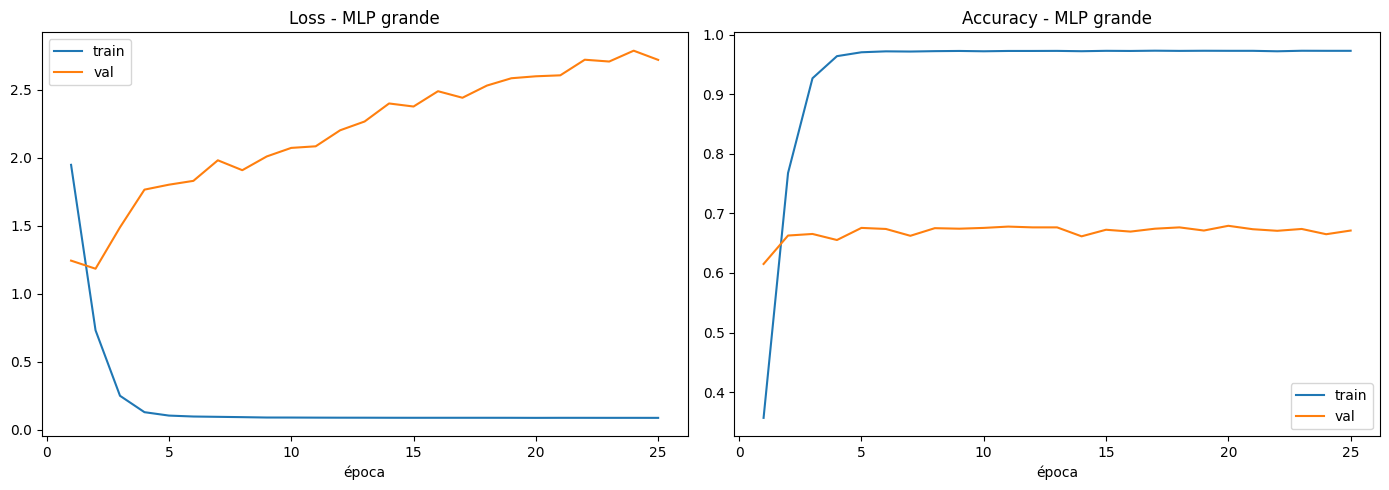

Mínimo de val_loss en la época 2: 1.1845 -> época final: 2.7212
train_acc final: 0.9729 | val_acc final: 0.6712


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, EPOCHS_OVERFIT + 1)
axes[0].plot(ep, hist_overfit["train_loss"], label="train")
axes[0].plot(ep, hist_overfit["val_loss"], label="val")
axes[0].set_title("Loss - MLP grande")
axes[1].plot(ep, hist_overfit["train_acc"], label="train")
axes[1].plot(ep, hist_overfit["val_acc"], label="val")
axes[1].set_title("Accuracy - MLP grande")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

min_ep = int(np.argmin(hist_overfit["val_loss"])) + 1
print(f"Mínimo de val_loss en la época {min_ep}: {min(hist_overfit['val_loss']):.4f} "
      f"-> época final: {hist_overfit['val_loss'][-1]:.4f}")
print(f"train_acc final: {hist_overfit['train_acc'][-1]:.4f} | val_acc final: {hist_overfit['val_acc'][-1]:.4f}")

## Experimento de overfitting

Red de 3 capas de 1024 neuronas (12.4 millones de parámetros, 19 veces más que el mejor MLP), entrenada 25 épocas.

- La loss de validación es mínima en la época 2 y después sube sin parar, de 1.18 a 2.72.
- En train la accuracy llega a 0.97 en la época 5, mientras que en validación queda estancada en 0.67.
- La accuracy de validación no baja aunque la loss se duplique. El modelo no cambia mucho sus respuestas, pero se vuelve cada vez más seguro de las que tiene mal.
- En train no llega al 100% porque el 2.9% de los documentos no tiene ninguna palabra del vocabulario. Todos se ven iguales para el modelo y no los puede distinguir.
- Cada época tardó 0.77 s, unas 3.5 veces más que el mejor MLP.

Es un caso claro de overfitting: la red memoriza el train pero no mejora con datos nuevos.

## 9. Comparación con Regresión Softmax

Se reentrena la regresión softmax del TP anterior en **este mismo hardware** (un `MLP` sin capas ocultas), con su mejor configuración: stopwords eliminadas, stemming, unigramas, `max_features=10000`, `min_df=1`, Adam, `lr=0.00924`, `batch_size=64`, 20 épocas.

In [26]:
sm_train, sm_test = preprocessed_cache[(True, "stem")]
X_sm_tr_sp, X_sm_te_sp, _ = vectorize_data(sm_train, sm_test, (1, 1), 10000, 1)
X_sm_tr, y_sm_tr = to_device(X_sm_tr_sp, y_train_full)
X_sm_te, y_sm_te = to_device(X_sm_te_sp, y_test)

torch.manual_seed(SEED)
softmax = MLP(X_sm_tr.shape[1], [], NUM_CLASSES)
opt_sm = optim.Adam(softmax.parameters(), lr=0.009236458062149249)

with mlflow.start_run(run_name="softmax_comparacion"):
    t0 = time.perf_counter()
    hist_sm = train_model(softmax, X_sm_tr, y_sm_tr, X_sm_te, y_sm_te, opt_sm,
                          EPOCHS_SOFTMAX, 64, run_name="softmax")
    softmax_time = time.perf_counter() - t0

[softmax] ep 1/20 - train_loss 2.3202 train_acc 0.5860 - val_loss 1.9074 val_acc 0.6645 - 0.24 s
[softmax] ep 2/20 - train_loss 1.3277 train_acc 0.8389 - val_loss 1.5229 val_acc 0.6768 - 0.22 s
[softmax] ep 3/20 - train_loss 0.9201 train_acc 0.8829 - val_loss 1.3571 val_acc 0.6768 - 0.32 s
[softmax] ep 4/20 - train_loss 0.7039 train_acc 0.9072 - val_loss 1.2731 val_acc 0.6767 - 0.46 s
[softmax] ep 5/20 - train_loss 0.5693 train_acc 0.9233 - val_loss 1.2259 val_acc 0.6754 - 0.36 s
[softmax] ep 6/20 - train_loss 0.4768 train_acc 0.9356 - val_loss 1.1974 val_acc 0.6733 - 0.23 s
[softmax] ep 7/20 - train_loss 0.4093 train_acc 0.9443 - val_loss 1.1800 val_acc 0.6718 - 0.25 s
[softmax] ep 8/20 - train_loss 0.3579 train_acc 0.9509 - val_loss 1.1697 val_acc 0.6729 - 0.23 s
[softmax] ep 9/20 - train_loss 0.3176 train_acc 0.9555 - val_loss 1.1634 val_acc 0.6701 - 0.23 s
[softmax] ep 10/20 - train_loss 0.2855 train_acc 0.9600 - val_loss 1.1612 val_acc 0.6690 - 0.23 s
[softmax] ep 11/20 - train_lo

In [27]:
comparacion = pd.DataFrame({
    "Regresión softmax": {
        "parámetros": count_params(softmax),
        "épocas": EPOCHS_SOFTMAX,
        "test_acc (época final)": hist_sm["val_acc"][-1],
        "test_acc (mejor época)": max(hist_sm["val_acc"]),
        "train_acc final": hist_sm["train_acc"][-1],
        "s por época": np.mean(hist_sm["epoch_time"]),
        "tiempo total (s)": softmax_time,
    },
    "MLP (mejor de Optuna)": {
        "parámetros": count_params(mlp_final),
        "épocas": BEST_EPOCHS,
        "test_acc (época final)": mlp_test_acc,
        "test_acc (mejor época)": max(hist_final["val_acc"]),
        "train_acc final": hist_final["train_acc"][-1],
        "s por época": np.mean(hist_final["epoch_time"]),
        "tiempo total (s)": mlp_final_time,
    },
})
print("Nota: 'mejor época' mira el test, se muestra solo como referencia (no se usa para elegir).")
comparacion.round(4)

Nota: 'mejor época' mira el test, se muestra solo como referencia (no se usa para elegir).


,Regresión softmax,MLP (mejor de Optuna)
parámetros,200020.0000,641364.0000
épocas,20.0000,6.0000
test_acc (época final),0.6557,0.6891
test_acc (mejor época),0.6768,0.6891
train_acc final,0.9709,0.9093
s por época,0.2545,0.2931
tiempo total (s),5.5272,1.8917


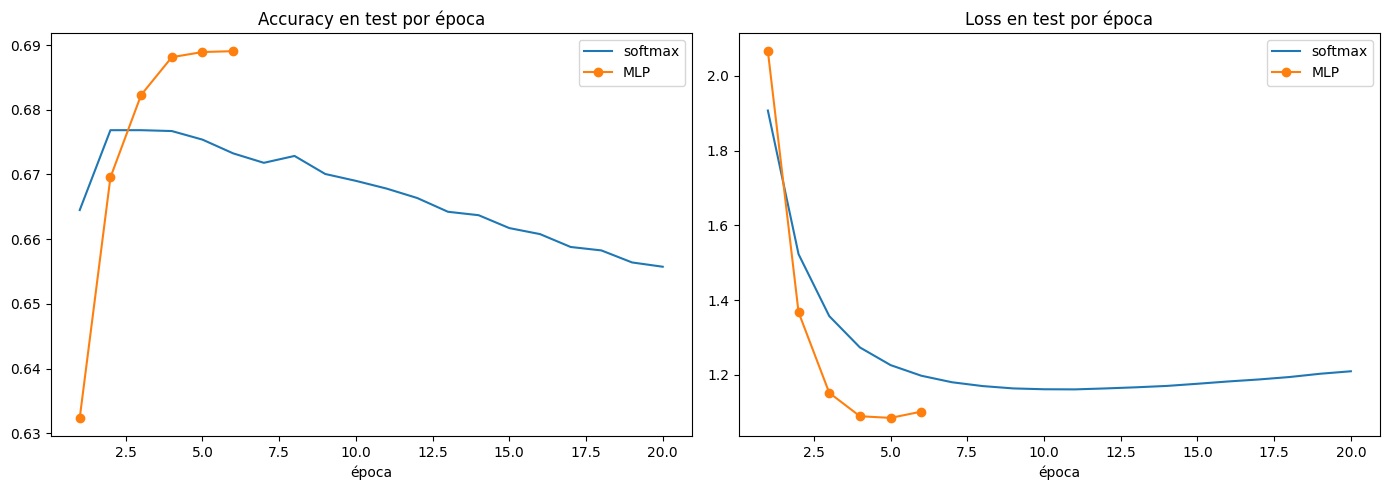

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, EPOCHS_SOFTMAX + 1), hist_sm["val_acc"], label="softmax")
axes[0].plot(range(1, BEST_EPOCHS + 1), hist_final["val_acc"], "o-", label="MLP")
axes[0].set_title("Accuracy en test por época")
axes[1].plot(range(1, EPOCHS_SOFTMAX + 1), hist_sm["val_loss"], label="softmax")
axes[1].plot(range(1, BEST_EPOCHS + 1), hist_final["val_loss"], "o-", label="MLP")
axes[1].set_title("Loss en test por época")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

## Comparación con Regresión Softmax

| | Regresión softmax | MLP |
|---|---|---|
| Parámetros | 200020 | 641364 |
| Mejor val_acc en la búsqueda | 0.7424 | 0.7428 |
| Épocas | 20 | 6 |
| Test accuracy | 0.6557 | 0.6891 |
| Segundos por época | 0.22 | 0.27 |
| Tiempo total | ≈4.5 s | 1.7 s |

- En validación los dos modelos dan prácticamente lo mismo.
- En test el MLP es unos 3 puntos mejor. Parte de esa ventaja viene de que el MLP paró en la época 6, mientras que la softmax siguió 20 épocas y fue empeorando.
- El MLP tiene 3 veces más parámetros, pero tarda solo un poco más por época y terminó antes porque necesitó menos épocas.
- Conclusión: agregar una capa oculta mejora poco. Casi todo el rendimiento ya lo logra el modelo lineal, y los errores entre categorías parecidas se mantienen.